In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option('display.max_columns', None)

# Display numbers with 2 decimal places
pd.set_option('display.float_format', '{:.2f}'.format)

print("Libraries imported successfully!")

Libraries imported successfully!


# SCENARIO

**The Scenario**
> A real estate investment firm aims to analyze the 2019 New York City short-term rental market to identify high yield property acquisition targets across the boroughs.

**Why It Fits**
> It contains missing review metrics, extreme price,  PII exposure`(host_name)` and geographic sampling bias.

**Questions To Be Answered**
> Which neighbourhood groups yield the highest average listing prices and how room types influence availability and review frequency.

# DATA SOURCE

Obtained from: Kaggle


URL: https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data

In [2]:
# Load dataset

url = "https://raw.githubusercontent.com/a213602-ukm/data-eng-assignment/refs/heads/main/AB_NYC_2019.csv"
df = pd.read_csv(url)


# DATA PROFILING & DIAGNOSTICS


In [3]:
# Initial data inspection

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.head()

Number of rows: 48895
Number of columns: 16


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.65,-73.97,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75,-73.98,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.81,-73.94,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.69,-73.96,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.80,-73.94,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
# Examine numerical columns
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,48895.00,48895.00,48895.00,48895.00,48895.00,48895.00,48895.00,38843.00,48895.00,48895.00
mean,19017143.24,67620010.65,40.73,-73.95,152.72,7.03,23.27,1.37,7.14,112.78
std,10983108.39,78610967.03,0.05,0.05,240.15,20.51,44.55,1.68,32.95,131.62
min,2539.00,2438.00,40.50,-74.24,0.00,1.00,0.00,0.01,1.00,0.00
25%,9471945.00,7822033.00,40.69,-73.98,69.00,1.00,1.00,0.19,1.00,0.00
50%,19677284.00,30793816.00,40.72,-73.96,106.00,3.00,5.00,0.72,1.00,45.00
75%,29152178.50,107434423.00,40.76,-73.94,175.00,5.00,24.00,2.02,2.00,227.00
max,36487245.00,274321313.00,40.91,-73.71,10000.00,1250.00,629.00,58.50,327.00,365.00


In [5]:
# Examine categorical columns
df.describe(include='object')

,name,host_name,neighbourhood_group,neighbourhood,room_type,last_review
count,48879,48874,48895,48895,48895,38843
unique,47905,11452,5,221,3,1764
top,Hillside Hotel,Michael,Manhattan,Williamsburg,Entire home/apt,2019-06-23
freq,18,417,21661,3920,25409,1413


In [6]:
# Check datatypes

print(df.dtypes)

id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object


,Missing Values,Missing Percentage (%)
reviews_per_month,10052,20.56
last_review,10052,20.56
host_name,21,0.04
name,16,0.03


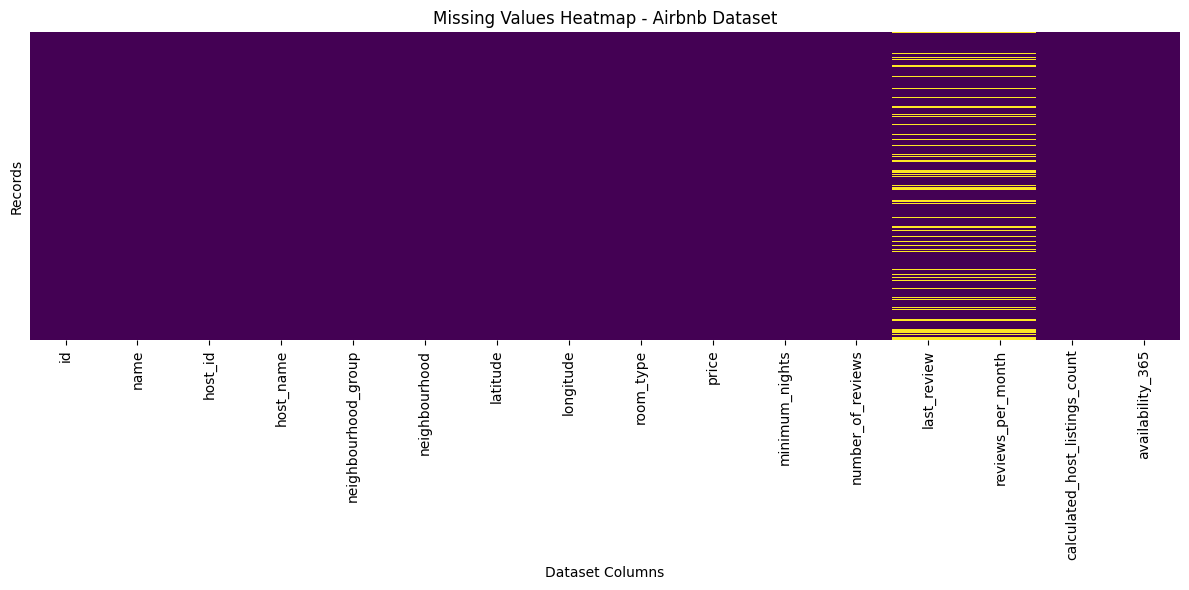

In [7]:
# Count missing values with percentage
missing_count = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage (%)': missing_percentage
})

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage (%)', ascending=False)

display(missing_summary)

# Visualising missing values using heatmap
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values Heatmap - Airbnb Dataset")
plt.xlabel("Dataset Columns")
plt.ylabel("Records")

plt.tight_layout()
plt.show()

In [8]:
# Check for duplicates
dup_count = df.duplicated().sum()

if dup_count == 0:
    print("No duplicate rows")
else:
    print(f"Found {dup_count} duplicate rows:")
    print(df[df.duplicated(keep=False)])

# Check for duplicate entries (based on ID)
dup_count = df["id"].duplicated().sum()

if dup_count == 0:
    print("No duplicate ID")
else:
    print(f"Found {dup_count} duplicate IDs:")
    print(df[df["id"].duplicated(keep=False)].sort_values("id"))

No duplicate rows
No duplicate ID


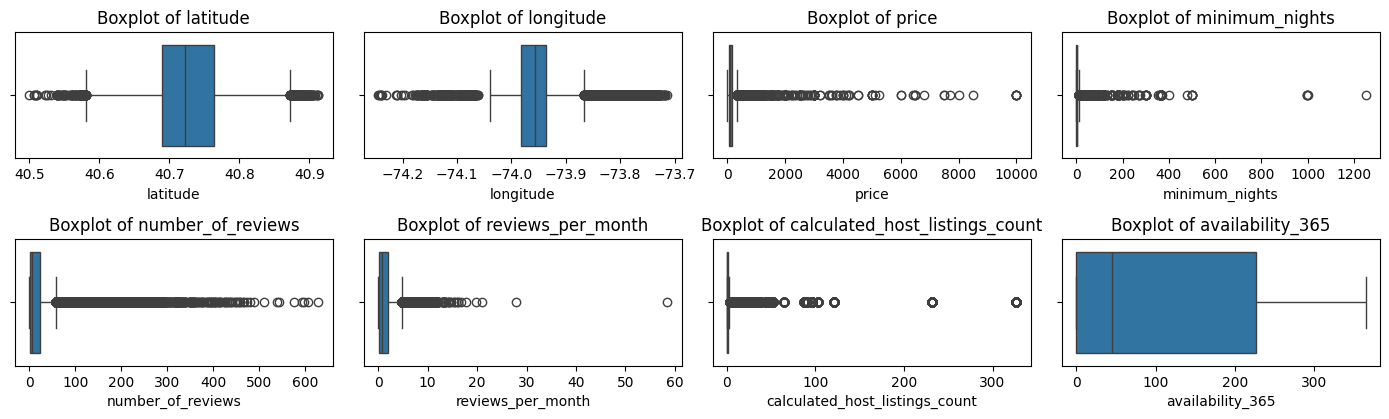

Outlier count:
latitude: 425
longitude: 2833
price: 2972
minimum_nights: 6607
number_of_reviews: 6021
reviews_per_month: 1793
calculated_host_listings_count: 7081
availability_365: 0


In [9]:
# Visually checking for outliers using boxplots
numerical_columns = df.select_dtypes(include="number").columns.drop(["id", "host_id"])

plt.figure(figsize=(14, 8))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(4, 4, i)
    sns.boxplot(x=df[column])
    plt.title(f'Boxplot of {column}')

plt.tight_layout()
plt.show()

# Calculate number of outliers using IQR

print("Outlier count:")
for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {outliers}")

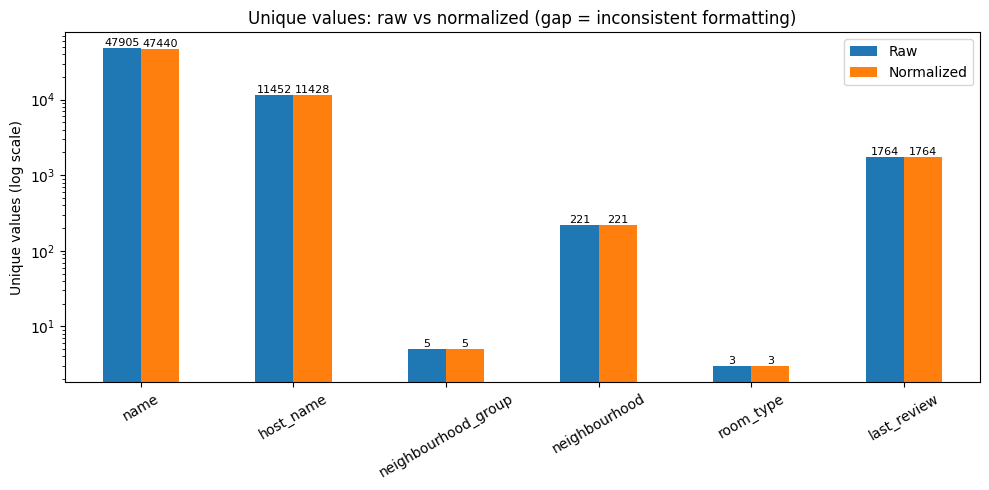

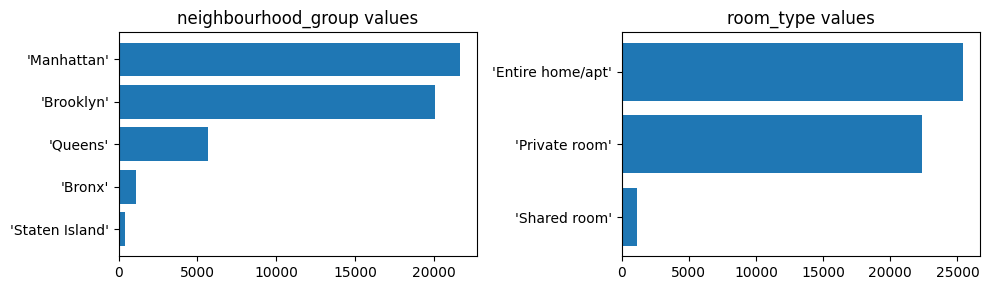

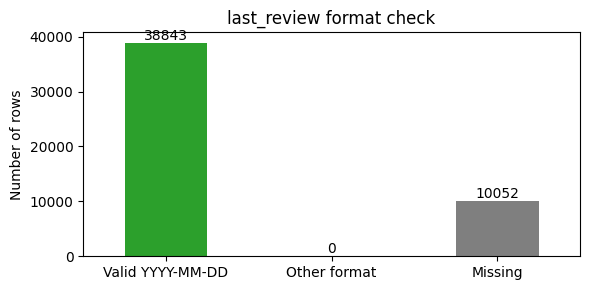

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

cat_cols = ["name", "host_name", "neighbourhood_group", "neighbourhood", "room_type", "last_review"]
text_cols = ["name", "host_name", "neighbourhood_group", "neighbourhood", "room_type"]

# Check for unique values before vs after simple cleaning
def normalize(s):
    return (s.dropna().astype(str)
             .str.strip().str.lower()
             .str.replace(r"\s+", " ", regex=True))

comp = pd.DataFrame({
    "Raw": df[cat_cols].nunique(),
    "Normalized": df[cat_cols].apply(lambda s: normalize(s).nunique())
})

ax = comp.plot(kind="bar", figsize=(10, 5), logy=True)
ax.set_title("Unique values: raw vs normalized (gap = inconsistent formatting)")
ax.set_ylabel("Unique values (log scale)")
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Visually checking formatting for columns 'neighbourhood_group' and 'room_type'
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, col in zip(axes, ["neighbourhood_group", "room_type"]):
    counts = df[col].value_counts()
    ax.barh([repr(v) for v in counts.index], counts.values)  # repr shows hidden spaces
    ax.set_title(f"{col} values")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Visually checking formatting for 'last_review' date
lr = df["last_review"]
parsed = pd.to_datetime(lr, format="%Y-%m-%d", errors="coerce")
status = pd.Series({
    "Valid YYYY-MM-DD": parsed.notna().sum(),
    "Other format":     (lr.notna() & parsed.isna()).sum(),
    "Missing":          lr.isna().sum(),
})

ax = status.plot(kind="bar", figsize=(6, 3), color=["tab:green", "tab:red", "tab:gray"])
ax.set_title("last_review format check")
ax.set_ylabel("Number of rows")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ISSUE HANDLING

**Missing Values**

In [11]:
# Impute missing reviews
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

# Flag missing dates (creates a boolean column)
df["has_reviews"] = df["last_review"].notna()

# Fill missing string values
df["name"] = df["name"].fillna("Unknown")
df["host_name"] = df["host_name"].fillna("Unknown")

A missing last_review most likely indicates the property has never been reviewed. Therefore, it is better to set the reviews per month to 0, instead of dropping 20% od the dataset. The missing string values (name, host_name) represent a fraction of a percent and can be filled with a placeholder to retain the rows.

**Handling Outliers**

In [12]:
# Cap price at the 99th percentile
price_99 = df["price"].quantile(0.99)
df["price"] = df["price"].clip(upper=price_99)

# Cap minimum_nights at 365 (1 year max makes logical sense for Airbnb)
df["minimum_nights"] = df["minimum_nights"].clip(upper=365)

Our IQR calculations shows that there are thousands of outliers in numerical columns such as price and minimum_nights. Instead of dropping thousands of outlier rows taht would result in significant data loss, we use the winsorizing technique to cap extreme values at lofical threshold. In this case we use the 99th percentile ofr price and a 365 day maximum for stays, to retain categorical data while neutralizing skewed numerical impact for future models.

**Fixing Inconsistent Formats and Data Types**

In [13]:
# Apply your normalization function to the actual dataframe
cat_cols = ["name", "neighbourhood_group", "neighbourhood", "room_type"]

for col in cat_cols:
    df[col] = (df[col].astype(str)
               .str.lower()
               .str.replace(r'[^\w\s]', '', regex=True)  # Removes punctuation
               .str.replace(r'\s+', ' ', regex=True)     # Normalizes multiple spaces
               .str.strip())

# Convert last_review to datetime datatype
df["last_review"] = pd.to_datetime(df["last_review"], format="%Y-%m-%d", errors="coerce")

We standardize text formats to prevent the same host or neighbours from being treated as multiple distinct categories due to capitalization, punctuation or trailing spaces. We also converted last_review to a datetime object to ensure the data type is valid for time-series operations.

# PII & BIAS RISK

**Sensitive or personally identifiable fields**

**PII RISK**

In [14]:
import hashlib

df = df.drop(columns=["host_name"])
df["host_id"] = df["host_id"].astype(str).apply(lambda x: hashlib.sha256(x.encode()).hexdigest()[:10])
df["latitude"] = df["latitude"].round(2)
df["longitude"] = df["longitude"].round(2)

# Flag listing names that may contain phone numbers or emails
flag = df["name"].str.contains(r"\d{3}[-.\s]?\d{3}[-.\s]?\d{4}|@", na=False)
print("Names with possible contact info:", flag.sum())

Names with possible contact info: 0


**Sampling bias**

In [15]:
for col in ["neighbourhood_group", "room_type"]:
    print(df[col].value_counts(normalize=True).mul(100).round(1), "\n")

small = df["neighbourhood"].value_counts()
print("Neighbourhoods with < 10 listings:", (small < 10).sum())

neighbourhood_group
manhattan       44.30
brooklyn        41.10
queens          11.60
bronx            2.20
staten island    0.80
Name: proportion, dtype: float64 

room_type
entire homeapt   52.00
private room     45.70
shared room       2.40
Name: proportion, dtype: float64 

Neighbourhoods with < 10 listings: 53


## PII and Bias Risks

### 1. PII risks and how I would handle them

| Field | Risk | Handling |
|---|---|---|
| `host_name` | Individual actual first name without any analysis to it | Drop the column. |
| `host_id` | A persistent ID which may be linked to an open-air-booking account owner's profile on airbnb. | Replacing by hash ID instead of dropping it. Calculated_host_listings_count is used at a host level of analysis latitude, longitude. |
| `latitude`, `longitude` | Identify an owner's residence particularly when there are multiple people living in it such as apartment/rooms. | Round coordinates to 2 decimal places(approx 1 km) or use a neighborhood instead.|
| `name` | Personal names, building names, phone numbers, or email addresses might be present in free text. | Scanning to find contacts, removing them,dropping coloumns as needed. |
| `last_review` | With location information combined with this data, we can determine if someone lived there at any point in time. | Keep just a year and month when precise date is not necessary.|



# CONCLUSION

The dataset is fit for the real estate investment scenario, providing sifficient level of detail across listing prices, room types, geographic locations and avalability metrics to evaluate potential high yield property acquisitions targets.

However, key limitations stil remain, which require pre-processing; approximately 20.56% of listings lack review history, extreme outliers in listing prices (up to $10000/night) distorting statistical averages, unmasked `host_name` entries pose PII privacy risks and heavy geographic sampling bias toward Manhattan and Brooklyn (representing over 85% of listings). This limits market visibility into under represented boroughs like Queens, Staten Island and The Bronx.

| Group Members | Matrics Number |
|----------|----------|
| AMMAR DANISH BIN MIZAL | A213602  |
| CHOONG CHENG KEN  | A213607  |
| MUHAMMAD FARISH HAYQAL BIN MUHAMMAD HAFIZ  | A212509  |
| MOHAMMAD SYAFIF BIN ROKEMAN  | A213604  |